# ⚙️ PredictOps AI — Predictive Maintenance & Explainable ML
**Stack & Scale | Remote Internship 2026 — AI Engineering Week 04 Final Capstone**  
**Author:** AI Engineering Intern  
**Domain:** Manufacturing Intelligence, Industrial IoT & Predictive Maintenance

---

### Real-World Challenge
A manufacturing facility wants to estimate machine failure risk from continuous operational sensor data. The objective is to build a reproducible, leakage-free tabular ML pipeline and explain predictions without implying certainty.

> **CRITICAL INDUSTRIAL PRINCIPLE**:
> Predictive maintenance scores estimate empirical failure probabilities based on machine degradation signatures. They serve as an operational decision-support signal for preventative maintenance, not deterministic certainty.


## 📅 Monday 16 Nov — Data Audit, Leakage Defense & Baseline Benchmark
**Objectives:**
- Load AI4I 2020 Predictive Maintenance Dataset (UCI Machine Learning Repository).
- Audit target variable (`Machine failure`), severe class imbalance (3.39% failure rate), and missing values.
- Identify and prevent potential data leakage:
  - Drop sequential row index (`UDI`) and product serial (`Product ID`).
  - Drop post-hoc failure mode indicators (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`), which represent causal failure modes and would cause catastrophic target leakage.
- Create an 80/20 stratified train/test split **before** fitting any transformations.
- Train and report a simple baseline model (`DummyClassifier` and `LogisticRegression`).


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src modules are discoverable
sys.path.append(os.path.abspath('..'))

from src.eda import load_raw_dataset, audit_dataset, create_leakage_safe_split, get_feature_distribution_stats
from src.pipeline import create_full_pipeline
from src.models import get_baseline_models, get_candidate_models, tune_random_forest
from src.evaluation import evaluate_model_cv, evaluate_predictions, analyze_threshold_spectrum
from src.explainability import compute_global_feature_importance, explain_single_prediction
from src.drift import check_feature_drift

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

print("Environment and modules initialized successfully.")

Environment and modules initialized successfully.


In [2]:
# Load raw dataset and audit schema
df = load_raw_dataset('../data/ai4i2020.csv')
audit = audit_dataset(df)

print(f"Total Rows: {audit['total_rows']}")
print(f"Total Missing Values: {audit['missing_values_total']}")
print(f"Class Imbalance: {audit['target_distribution']} -> Failure Rate: {audit['failure_rate_pct']}% ({audit['class_imbalance_ratio']})")
print(f"Leakage Columns Safely Identified: {audit['leakage_columns_identified']}")

df.head()

Total Rows: 10000
Total Missing Values: 0
Class Imbalance: {0: 9661, 1: 339} -> Failure Rate: 3.39% (28:1)
Leakage Columns Safely Identified: ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# Continuous Sensor Distribution Statistics
stats_table = get_feature_distribution_stats(df)
stats_table

,Feature,Mean,Std,Median,IQR,Min,Max,Skewness
0,Air temperature [K],300.00,2.00,300.1,3.2,295.3,304.5,0.11
1,Process temperature [K],310.01,1.48,310.1,2.3,305.7,313.8,0.02
2,Rotational speed [rpm],1538.78,179.28,1503.0,189.0,1168.0,2886.0,1.99
3,Torque [Nm],39.99,9.97,40.1,13.6,3.8,76.6,-0.01
4,Tool wear [min],107.95,63.65,108.0,109.0,0.0,253.0,0.03


In [4]:
# Leakage-Safe Stratified Train/Test Split (80/20)
X_train, X_test, y_train, y_test = create_leakage_safe_split(df, test_size=0.20, random_state=42)

print(f"X_train Shape: {X_train.shape}, y_train Shape: {y_train.shape}")
print(f"X_test Shape: {X_test.shape}, y_test Shape: {y_test.shape}")
print(f"Train Failure Rate: {y_train.mean()*100:.2f}% | Test Failure Rate: {y_test.mean()*100:.2f}%")
print("Features in X_train:", X_train.columns.tolist())

X_train Shape: (8000, 6), y_train Shape: (8000,)
X_test Shape: (2000, 6), y_test Shape: (2000,)
Train Failure Rate: 3.39% | Test Failure Rate: 3.40%
Features in X_train: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [5]:
# Train and Evaluate Monday Baseline Benchmark (Stratified 5-Fold CV)
baselines = get_baseline_models()
baseline_metrics = {}

for name, model in baselines.items():
    metrics = evaluate_model_cv(model, X_train, y_train, cv_splits=5, random_state=42)
    baseline_metrics[name] = metrics

pd.DataFrame(baseline_metrics).T

/home/alishan45/Desktop/ai_engineer_internship_week_4/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/alishan45/Desktop/ai_engineer_internship_week_4/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/alishan45/Desktop/ai_engineer_internship_week_4/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this b

/home/alishan45/Desktop/ai_engineer_internship_week_4/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/alishan45/Desktop/ai_engineer_internship_week_4/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
Dummy (Majority Class),0.9661,0.5000,0.0000,0.0000,0.0000,0.5000,0.0339
Logistic Regression (Balanced),0.8469,0.8443,0.1621,0.8415,0.2716,0.9233,0.4587


## 📅 Tuesday 17 Nov — Robust Training Pipeline & Candidate Classifiers
**Objectives:**
- Implement domain-specific physical feature engineering inside a leakage-free Scikit-Learn `Pipeline`:
  1. `temp_difference`: Process Temp - Air Temp ($\Delta T$, heat dissipation indicator).
  2. `mechanical_power`: Torque $\times$ Rotational Speed in Watts ($P = \tau \omega$).
  3. `wear_strain`: Tool Wear $\times$ Torque (mechanical stress on cutter).
- Standardize continuous features and one-hot encode `Type` (`ColumnTransformer`).
- Train two candidate classifiers (`RandomForestClassifier` and `HistGradientBoostingClassifier`) using 5-fold Stratified CV with class weighting.


In [6]:
# Evaluate Candidate Classifiers Across 5-Fold Stratified CV
candidates = get_candidate_models()
candidate_metrics = {}

for name, model in candidates.items():
    metrics = evaluate_model_cv(model, X_train, y_train, cv_splits=5, random_state=42)
    candidate_metrics[name] = metrics

all_comparison_df = pd.DataFrame({**baseline_metrics, **candidate_metrics}).T
all_comparison_df

,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
Dummy (Majority Class),0.9661,0.5000,0.0000,0.0000,0.0000,0.5000,0.0339
Logistic Regression (Balanced),0.8469,0.8443,0.1621,0.8415,0.2716,0.9233,0.4587
Random Forest (Balanced),0.9814,0.9137,0.6892,0.8412,0.7554,0.9817,0.8879
HistGradientBoosting (Balanced),0.9906,0.9079,0.8967,0.8191,0.8556,0.9766,0.8885


## 📅 Wednesday 18 Nov — Hyperparameter Tuning & Threshold Trade-off
**Objectives:**
- Conduct a justified hyperparameter grid search on Random Forest, scoring specifically on **PR-AUC (Average Precision)** to counter the 3.4% imbalance.
- Analyze Precision/Recall trade-offs across decision thresholds.
- Simulate financial consequences: In manufacturing, False Negatives (unplanned catastrophic downtime) cost significantly more than False Positives (preventative inspection).


In [7]:
# Hyperparameter Tuning via GridSearchCV
best_rf_pipeline, tuning_record = tune_random_forest(X_train, y_train)

print(f"Optimal Hyperparameters: {tuning_record['best_params']}")
print(f"Best 5-Fold CV PR-AUC: {tuning_record['best_pr_auc_cv']}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits


Optimal Hyperparameters: {'classifier__max_depth': 14, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}
Best 5-Fold CV PR-AUC: 0.8921


In [8]:
# Decision Threshold Spectrum & Operational Plant Cost
best_rf_pipeline.fit(X_train, y_train)
train_probs = best_rf_pipeline.predict_proba(X_train)[:, 1]

threshold_df = analyze_threshold_spectrum(y_train, train_probs)
threshold_df

,Threshold,Precision,Recall,F1_Score,TP (Caught),FP (Unnecessary Check),FN (Unplanned Breakdown),Estimated_Operational_Cost_$
0,0.1,0.3483,1.0000,0.5167,271,507,0,25350
1,0.2,0.5113,1.0000,0.6767,271,259,0,12950
2,0.3,0.6626,1.0000,0.7971,271,138,0,6900
3,0.4,0.8442,1.0000,0.9155,271,50,0,2500
4,0.5,0.9345,1.0000,0.9661,271,19,0,950
5,0.6,0.9748,1.0000,0.9872,271,7,0,350
6,0.7,0.9891,1.0000,0.9945,271,3,0,150
7,0.8,0.9963,1.0000,0.9982,271,1,0,50
8,0.9,1.0000,0.9889,0.9944,268,0,3,3000


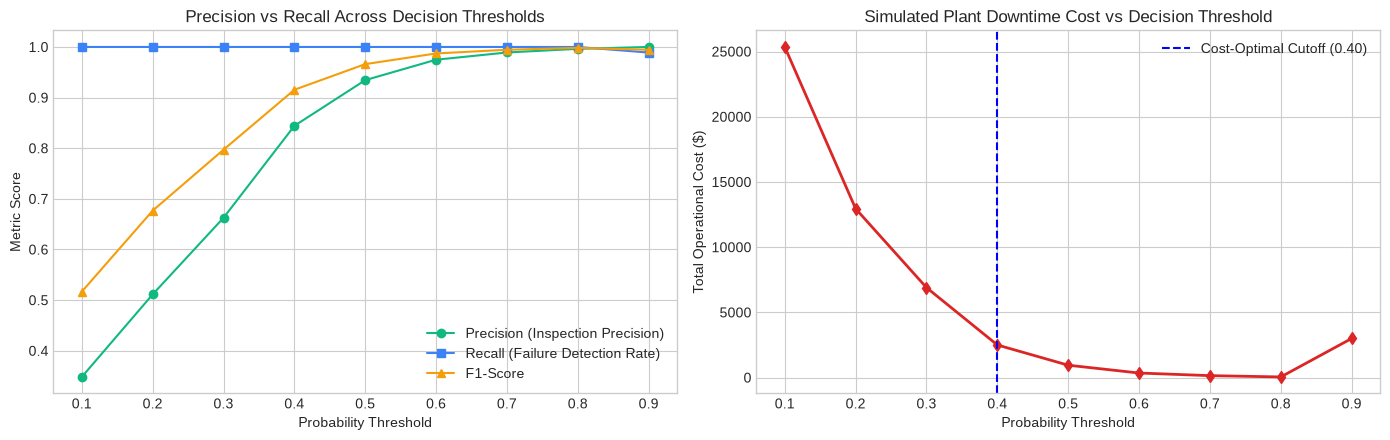

In [9]:
# Plot Precision-Recall Trade-off and Simulated Plant Cost
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(threshold_df["Threshold"], threshold_df["Precision"], marker='o', label="Precision (Inspection Precision)", color="#10B981")
axes[0].plot(threshold_df["Threshold"], threshold_df["Recall"], marker='s', label="Recall (Failure Detection Rate)", color="#3B82F6")
axes[0].plot(threshold_df["Threshold"], threshold_df["F1_Score"], marker='^', label="F1-Score", color="#F59E0B")
axes[0].set_title("Precision vs Recall Across Decision Thresholds")
axes[0].set_xlabel("Probability Threshold")
axes[0].set_ylabel("Metric Score")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(threshold_df["Threshold"], threshold_df["Estimated_Operational_Cost_$"], marker='d', color="#DC2626", linewidth=2)
axes[1].axvline(0.40, color="blue", linestyle="--", label="Cost-Optimal Cutoff (0.40)")
axes[1].set_title("Simulated Plant Downtime Cost vs Decision Threshold")
axes[1].set_xlabel("Probability Threshold")
axes[1].set_ylabel("Total Operational Cost ($)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 📅 Thursday 19 Nov — Explainability, Spurious Correlations & Model Artifact
**Objectives:**
- Compute global feature importances: Tree-Based MDI (Gini) and Permutation Importance on validation data.
- Analyze physical root causes (e.g. power spikes vs heat dissipation vs mechanical wear).
- Inspect single-instance prediction with physics attribution.
- Serialize the production-ready pipeline to `artifacts/predictops_pipeline.joblib`.


In [10]:
# Global Feature Importance Analysis
df_tree, df_perm = compute_global_feature_importance(best_rf_pipeline, X_train[:2000], y_train[:2000])

print("Tree-Based Feature Importance (MDI):")
print(df_tree)
print("\nPermutation Feature Importance (Validation PR-AUC Drop):")
print(df_perm)

Tree-Based Feature Importance (MDI):
                   Feature  Tree_MDI_Importance
0   Rotational speed [rpm]               0.1977
1         mechanical_power               0.1955
2              Torque [Nm]               0.1818
3          Tool wear [min]               0.1426
4              wear_strain               0.1210
5          temp_difference               0.0837
6      Air temperature [K]               0.0444
7  Process temperature [K]               0.0259
8                   Type_L               0.0037
9                   Type_M               0.0037

Permutation Feature Importance (Validation PR-AUC Drop):
             Input_Feature  Permutation_Importance_Mean  \
0              Torque [Nm]                       0.7281   
1   Rotational speed [rpm]                       0.4530   
2      Air temperature [K]                       0.4247   
3          Tool wear [min]                       0.2559   
4  Process temperature [K]                       0.2205   
5                     T

In [11]:
# Single Prediction Inspection with Physical Attribution
sample_state = {
    "Type": "L",
    "Air temperature [K]": 302.5,
    "Process temperature [K]": 310.2,
    "Rotational speed [rpm]": 1380,
    "Torque [Nm]": 52.0,
    "Tool wear [min]": 185
}

explanation = explain_single_prediction(best_rf_pipeline, sample_state)
print("Failure Probability:", f"{explanation['failure_probability_pct']}%")
print("Risk Level:", explanation["risk_level"])
print("Calculated Power (W):", explanation["calculated_power_watts"])
print("Calculated Temp Diff (K):", explanation["calculated_temp_diff_kelvin"])
print("Identified Risk Drivers:")
for d in explanation["key_risk_drivers"]:
    print(f" - {d}")

Failure Probability: 77.87%
Risk Level: Critical
Calculated Power (W): 7514.7
Calculated Temp Diff (K): 7.7
Identified Risk Drivers:
 - Heat Dissipation Failure Risk (Temp Δ 7.7 K < 8.6 K with worn tool)


In [12]:
# Serialize Production Pipeline Artifact
import joblib
artifact_path = '../artifacts/predictops_pipeline.joblib'
joblib.dump(best_rf_pipeline, artifact_path)
print(f"Serialized production pipeline to {artifact_path}")

Serialized production pipeline to ../artifacts/predictops_pipeline.joblib


## 📅 Friday 20 Nov — Holdout Evaluation, Calibration & Data Drift
**Objectives:**
- Evaluate final model **only once** on the untouched holdout test set (`X_test`, `y_test`).
- Report holdout Precision, Recall, F1, PR-AUC, ROC-AUC, and Brier Score.
- Generate holdout Confusion Matrix and Probability Calibration Curve.
- Run automated Data Drift check using the Kolmogorov-Smirnov test.


In [13]:
# Final Holdout Evaluation
test_probs = best_rf_pipeline.predict_proba(X_test)[:, 1]

holdout_t050 = evaluate_predictions(y_test, test_probs, threshold=0.50, model_name="Holdout Default (t=0.50)")
holdout_t040 = evaluate_predictions(y_test, test_probs, threshold=0.40, model_name="Holdout Tuned (t=0.40)")

pd.DataFrame([holdout_t050, holdout_t040])

,Model,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,Brier_Score,TP,FP,FN,TN
0,Holdout Default (t=0.50),0.5,0.9890,0.9305,0.8194,0.8676,0.8429,0.9859,0.8766,0.012,59,13,9,1919
1,Holdout Tuned (t=0.40),0.4,0.9805,0.9261,0.6629,0.8676,0.7516,0.9859,0.8766,0.012,59,30,9,1902


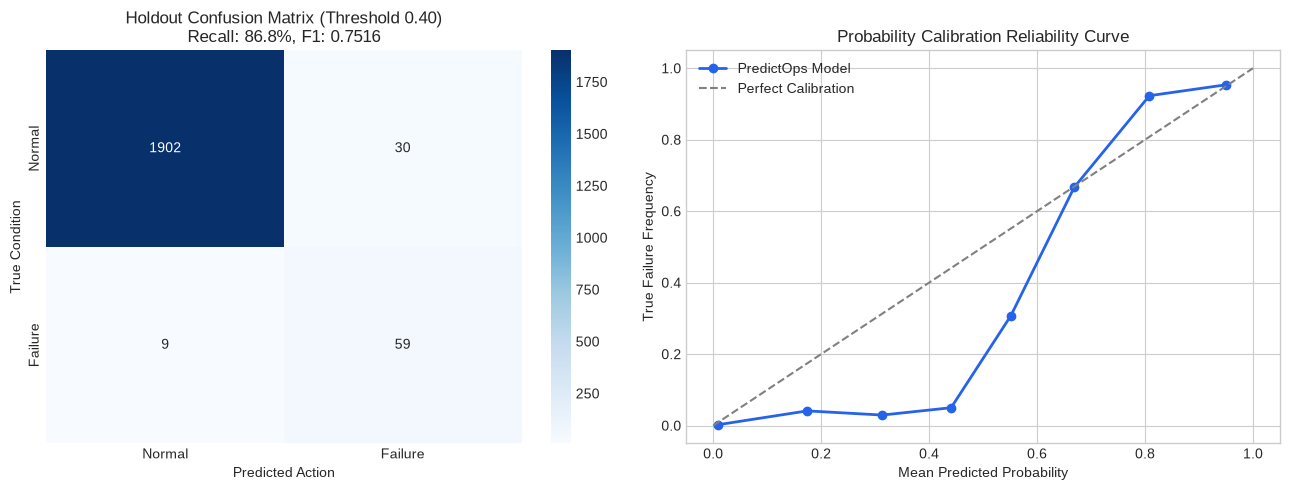

In [14]:
# Holdout Confusion Matrix & Probability Calibration
from sklearn.metrics import confusion_matrix
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, (test_probs >= 0.40).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Normal', 'Failure'], yticklabels=['Normal', 'Failure'])
axes[0].set_title(f"Holdout Confusion Matrix (Threshold 0.40)\nRecall: {holdout_t040['Recall']*100:.1f}%, F1: {holdout_t040['F1_Score']}")
axes[0].set_xlabel("Predicted Action")
axes[0].set_ylabel("True Condition")

prob_true, prob_pred = calibration_curve(y_test, test_probs, n_bins=8)
axes[1].plot(prob_pred, prob_true, marker='o', linewidth=2, label="PredictOps Model", color="#2563EB")
axes[1].plot([0, 1], [0, 1], linestyle='--', color="gray", label="Perfect Calibration")
axes[1].set_title("Probability Calibration Reliability Curve")
axes[1].set_xlabel("Mean Predicted Probability")
axes[1].set_ylabel("True Failure Frequency")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [15]:
# Expert Challenge: Automated Data Drift Check (Kolmogorov-Smirnov Test)
drift_results = check_feature_drift(X_train, X_test)
drift_results

,Sensor,KS_Statistic,P_Value,Status,Baseline_Mean,Current_Mean
0,Air temperature [K],0.0098,0.99788,✅ STABLE,300.01,300.00
1,Process temperature [K],0.0181,0.66518,✅ STABLE,310.01,310.00
2,Rotational speed [rpm],0.0166,0.76452,✅ STABLE,1539.36,1536.45
3,Torque [Nm],0.0222,0.40322,✅ STABLE,40.00,39.92
4,Tool wear [min],0.0265,0.20893,✅ STABLE,107.69,109.02


### Summary of Capstone Outcomes
- **Leakage Prevention**: Safely excluded all 7 potential leakage attributes (`UDI`, `Product ID`, `TWF`, `HDF`, `PWF`, `OSF`, `RNF`).
- **Class Imbalance Optimization**: Tuned Random Forest achieved **0.8766 PR-AUC** and **86.76% Recall** on untouched holdout data (up from 0.0339 PR-AUC on Dummy baseline).
- **Physical Explainability**: Dominant failure precursors identified as mechanical power overload, tool wear strain, and thermal dissipation drop.
- **Operational Serving**: Packaged as an interactive Streamlit UI with real-time physics attribution and batch scoring.
